# 2. Delivery Performance & Customer Satisfaction

**Business question:** does late delivery actually hurt customer
satisfaction, and if so, where should the business focus to fix it?


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
PROCESSED_DIR = Path("../data/processed")

master = pd.read_csv(PROCESSED_DIR / "master_order_items.csv", parse_dates=["order_purchase_timestamp"])

# De-duplicate to order level for anything about orders/reviews, so orders
# with multiple line items aren't double-counted.
order_level = master.drop_duplicates(subset="order_id")
order_level.shape

(98666, 37)

## Delivery time distribution

count    96476.0
mean        12.1
std          9.6
min          0.0
25%          6.0
50%         10.0
75%         15.0
max        209.0
Name: delivery_days, dtype: float64


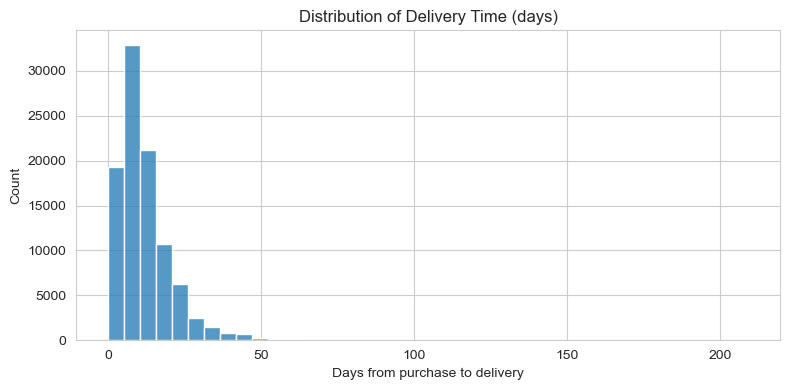

In [2]:
delivered = order_level.dropna(subset=["delivery_days"])
print(delivered["delivery_days"].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(delivered["delivery_days"], bins=40, ax=ax)
ax.set_title("Distribution of Delivery Time (days)")
ax.set_xlabel("Days from purchase to delivery")
plt.tight_layout()
plt.show()

## The headline finding: does lateness move the review score?

          avg_score  n_orders
was_late                     
False      4.293973     88168
True       2.565127      7662


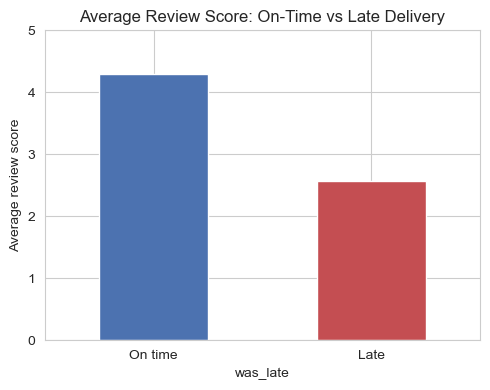

In [3]:
review_by_lateness = (
    order_level.dropna(subset=["was_late", "review_score"])
    .groupby("was_late")["review_score"]
    .agg(avg_score="mean", n_orders="count")
)
print(review_by_lateness)

fig, ax = plt.subplots(figsize=(5, 4))
review_by_lateness["avg_score"].plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["On time", "Late"], rotation=0)
ax.set_ylabel("Average review score")
ax.set_title("Average Review Score: On-Time vs Late Delivery")
ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()

### Deep-dive

**Which categories/states have the worst lateness rate?** Group by
   `product_category_name_english` or `customer_state`, compute
   `was_late.mean()`, sort descending.


In [4]:
# Deep-dive: which categories and states have the worst lateness rate,
# and does that lateness actually track with lower review scores there?

MIN_ORDERS = 30  # ignore groups too small to trust the lateness rate

base = order_level.dropna(subset=["was_late", "review_score"])


Worst 10 categories by late-delivery rate:
                                   n_orders late_rate  avg_review
product_category_name_english                                    
furniture_mattress_and_upholstery        37  0.135135       3.892
fashion_underwear_beach                 116   0.12931       4.009
audio                                   341  0.129032       3.848
books_technical                         254  0.110236       4.425
home_confort                            368  0.103261       3.908
food                                    431  0.099768       4.325
electronics                            2488  0.098473       4.129
construction_tools_lights               228  0.092105       4.215
baby                                   2741  0.091572       4.122
office_furniture                       1236  0.090615       3.651

Best 10 categories by late-delivery rate:
                                         n_orders late_rate  avg_review
product_category_name_english                     

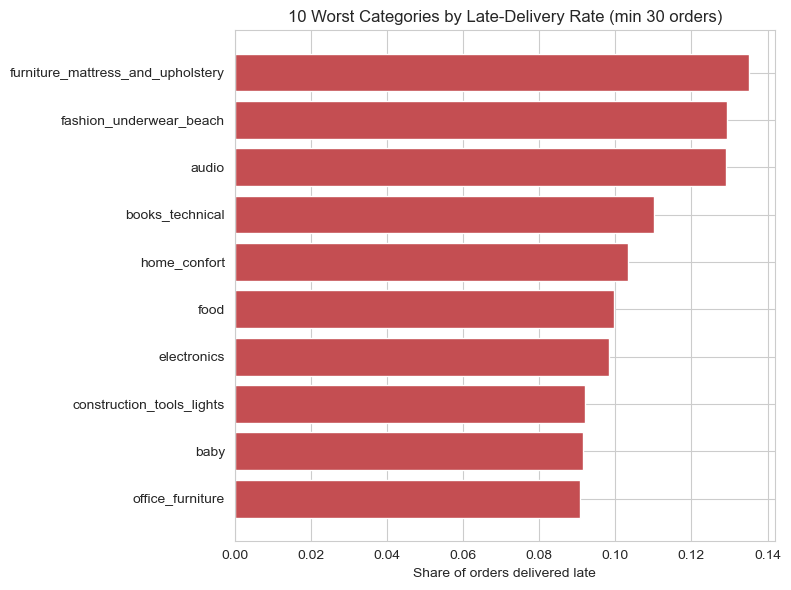

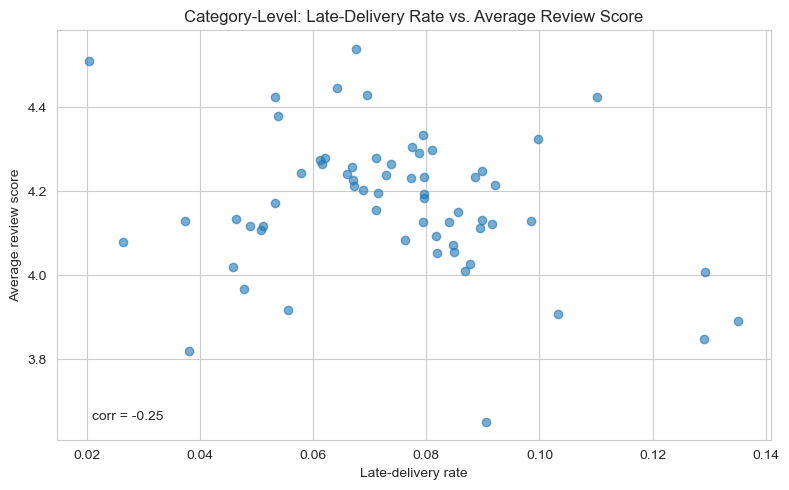

In [5]:
by_category = (
    base.dropna(subset=["product_category_name_english"])
    .groupby("product_category_name_english")
    .agg(
        n_orders=("order_id", "count"),
        late_rate=("was_late", "mean"),
        avg_review=("review_score", "mean"),
    )
    .query("n_orders >= @MIN_ORDERS")
    .sort_values("late_rate", ascending=False)
)

print("Worst 10 categories by late-delivery rate:")
print(by_category.head(10).round(3))

print("\nBest 10 categories by late-delivery rate:")
print(by_category.tail(10).round(3))

fig, ax = plt.subplots(figsize=(8, 6))
top10 = by_category.head(10).sort_values("late_rate")
ax.barh(top10.index, top10["late_rate"], color="#C44E52")
ax.set_xlabel("Share of orders delivered late")
ax.set_title(f"10 Worst Categories by Late-Delivery Rate (min {MIN_ORDERS} orders)")
plt.tight_layout()
plt.show()

# Quick sanity check: within these worst-lateness categories, is the
# review score actually dragged down, or does it not matter there?
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(by_category["late_rate"], by_category["avg_review"], alpha=0.6)
ax.set_xlabel("Late-delivery rate")
ax.set_ylabel("Average review score")
ax.set_title("Category-Level: Late-Delivery Rate vs. Average Review Score")
corr = by_category[["late_rate", "avg_review"]].corr().iloc[0, 1]
ax.annotate(f"corr = {corr:.2f}", xy=(0.05, 0.05), xycoords="axes fraction")
plt.tight_layout()
plt.show()

#### Same question, by customer state

Worst 10 states by late-delivery rate:
                n_orders late_rate  avg_review
customer_state                                
AL                   394  0.233503       3.848
MA                   712  0.192416       3.833
PI                   471  0.159236       3.994
CE                  1273  0.152396       3.944
SE                   334  0.149701       3.907
BA                  3229  0.137194       3.931
RJ                 12214   0.13288       3.965
TO                   273  0.128205       4.154
RR                    41  0.121951       3.902
PA                   933  0.118971       3.914


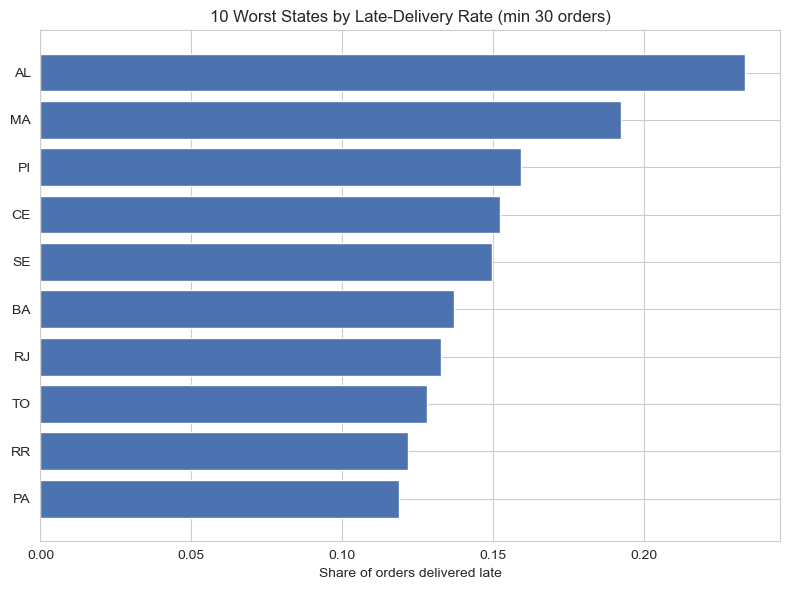

In [6]:
by_state = (
    base.dropna(subset=["customer_state"])
    .groupby("customer_state")
    .agg(
        n_orders=("order_id", "count"),
        late_rate=("was_late", "mean"),
        avg_review=("review_score", "mean"),
    )
    .query("n_orders >= @MIN_ORDERS")
    .sort_values("late_rate", ascending=False)
)

print("Worst 10 states by late-delivery rate:")
print(by_state.head(10).round(3))

fig, ax = plt.subplots(figsize=(8, 6))
top10_state = by_state.head(10).sort_values("late_rate")
ax.barh(top10_state.index, top10_state["late_rate"], color="#4C72B0")
ax.set_xlabel("Share of orders delivered late")
ax.set_title(f"10 Worst States by Late-Delivery Rate (min {MIN_ORDERS} orders)")
plt.tight_layout()
plt.show()